In [72]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd

%pip install ucimlrepo

from ucimlrepo import fetch_ucirepo, list_available_datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.linear_model import LogisticRegression

Note: you may need to restart the kernel to use updated packages.


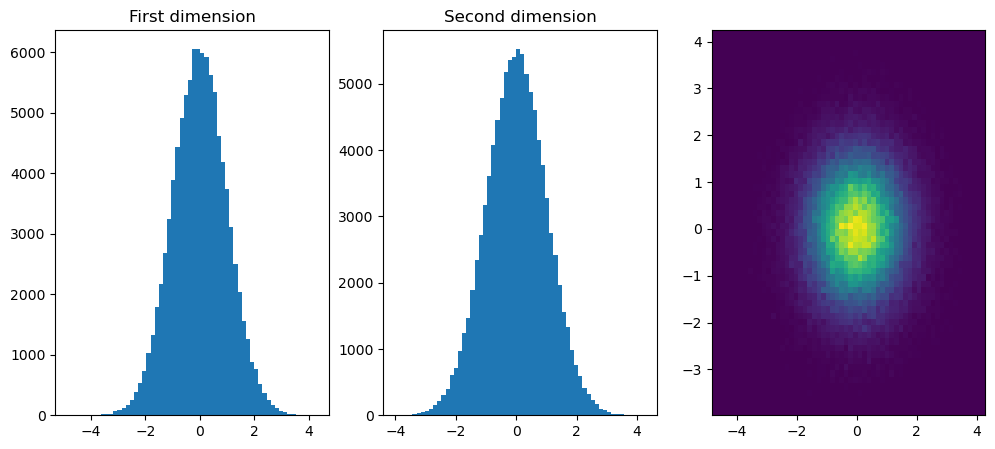

In [3]:
n = 100000
np.random.seed(0)

def generate_x(n,d=2):
    #return np.random.multivariate_normal(np.zeros(d), np.ones((d,d)), n)
    return np.random.multivariate_normal(np.zeros(d), np.eye(d), n)

#print(sampling_x(100, 2))

def plot_multivariate(n):
    x = generate_x(n)
    fig,ax = plt.subplots(1, 3, figsize=(12, 5))

    ax[0].hist(x[:,0], bins=60, label='first dimension')
    ax[0].set_title('First dimension')
    ax[1].hist(x[:,1], bins=60, label='second dimension')
    ax[1].set_title('Second dimension')

    ax[2].hist2d(x[:,0], x[:,1], bins=60 , density=True)
    plt.show()

plot_multivariate(n)

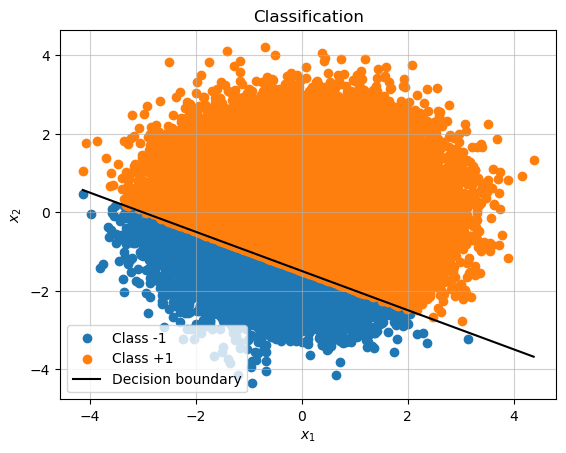

In [4]:
def generate_xy(n,w_star,tau_star):
    x = generate_x(n)
    y = np.array([np.sign(np.dot(w_star, x[i]) + tau_star) for i in range(n)])

    return x,y

w_star = (1,2) #meaning that the boundary is at y=-x/2 if tau=0
tau_star = 3

x,y = generate_xy(n, w_star, tau_star)

def plot_boundary(x, y, w_star, tau_star):
    plt.figure()
    plt.scatter(x[y == -1, 0], x[y == -1, 1], label='Class -1')
    plt.scatter(x[y == 1, 0], x[y == 1, 1], label='Class +1')

    # Decision boundary: w1*x1 + w2*x2 + tau = 0
    x_axis = np.linspace(x[:, 0].min(), x[:, 0].max(), 100)
    y_axis = -(w_star[0] * x_axis + tau_star) / w_star[1]

    plt.plot(x_axis, y_axis, 'k', label='Decision boundary')

    plt.title('Classification')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.legend()
    plt.grid(alpha=0.6)
    
plot_boundary(x,y, w_star, tau_star)


In [5]:
def w_grad(w, tau, x_i, y_i):
    return -2*(y_i - np.dot(w,x_i) - tau)*x_i

def tau_grad(w, tau, x_i, y_i):
    return -2*(y_i - np.dot(w,x_i) - tau)

def SGD(x, y, eta, n_epochs, use_mini_batch=True, n_batch=10):
    n,d = x.shape
    w = np.ones(d)
    tau = 5

    w_history = [w.copy()]
    tau_history = [tau]

    for epoch in range(n_epochs):
        indices = np.random.permutation(n)

        if use_mini_batch:
            x_batches = np.array_split(x[indices], n_batch)
            y_batches = np.array_split(np.array(y)[indices], n_batch)

            for x_batch, y_batch in zip(x_batches, y_batches):
                grad = -2*(y_batch - x_batch @ w - tau)

                grad_w = np.mean(grad[:, None]*x_batch, axis=0)
                grad_tau = np.mean(grad)

                w -= eta*grad_w
                tau -= eta*grad_tau

                w_history.append(w.copy())
                tau_history.append(tau)

        else:
            for idx in indices:
                grad_w = w_grad(w, tau, x[idx], y[idx])
                grad_tau = tau_grad(w, tau, x[idx], y[idx])

                w -= eta*grad_w
                tau -= eta*grad_tau

                w_history.append(w.copy())
                tau_history.append(tau)

    return np.array(w_history), np.array(tau_history)


In [6]:
w_history, tau_history = SGD(x, y, eta=0.01, n_epochs=30, use_mini_batch=True, n_batch=10)

print("w :", w_history[-1], "tau :", tau_history[-1])

w : [0.14302813 0.28572433] tau : 0.8329115668137874


Cosine similarity: 0.9999998920859284


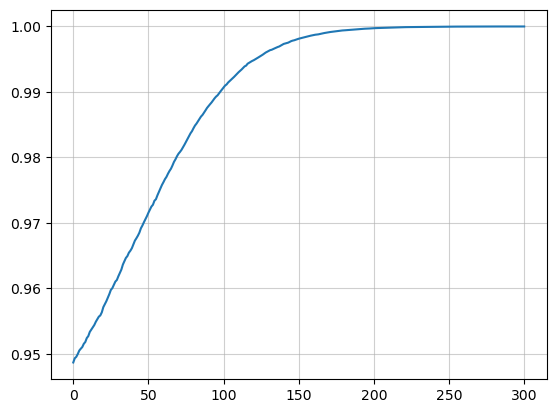

In [7]:
def cosine_sim(w,w_star):
    return np.dot(w, w_star) / (np.linalg.norm(w) * np.linalg.norm(w_star))

cos_sim = cosine_sim(w_history[-1], w_star)
print("Cosine similarity:", cos_sim)

def plot_history(w_history, w_star):
    n = len(w_history)
    w_cosine_sim = [cosine_sim(w_history[i], w_star) for i in range(n)]

    plt.figure()
    plt.grid(alpha=0.6)
    plt.plot(w_cosine_sim)

plot_history(w_history, w_star)

In [8]:
def generate_x_noisy(x, n, s=0.5, d=2):
    eps = np.random.multivariate_normal(np.zeros(d), s**2*np.eye(d), n)
    return x+eps

In [9]:
x_noisy = generate_x_noisy(x, n)
w_history_noisy, tau_history_noisy = SGD(x_noisy, y, eta=0.01, n_epochs=30, use_mini_batch=True, n_batch=10)

print("w :", w_history_noisy[-1], "tau :", tau_history_noisy[-1])

w : [0.11245538 0.22752271] tau : 0.833334063206456


In [44]:
### from the ucimlrepo github ###

#list_available_datasets()

# import dataset
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features
Y = heart_disease.data.targets

print(heart_disease.metadata)
print(heart_disease.variables)

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [52]:
df = pd.concat([X, Y], axis=1)
df = df.dropna()

def disease_sign(x):
    if x>0:
        return 1
    else:
        return -1    

df['num'] = df['num'].map(disease_sign)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,-1
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,-1
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57,0,4,140,241,0,0,123,1,0.2,2,0.0,7.0,1
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,1
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,1


In [60]:
train, test = train_test_split(df, test_size=0.2, stratify=df['num'])
scaler = StandardScaler()

X_train = scaler.fit_transform(train.drop(columns='num'))
Y_train = train['num']
X_test = scaler.transform(test.drop(columns='num'))
Y_test = test['num']

In [ ]:
w_disease, tau_disease = SGD(X_train, Y_train, eta=0.01, n_epochs=30, use_mini_batch=True, n_batch=10)

In [71]:
scores = X_test @ w_disease[-1] + tau_disease[-1]

y_pred = np.where(scores>0,1,-1)
acc = accuracy_score(Y_test, y_pred)
auc = roc_auc_score(Y_test, scores)

print(acc, auc)

0.85 0.8939732142857143


In [75]:
# using the documentation of sklearn
clf = LogisticRegression(random_state=0).fit(X_train, Y_train)
y_pred_sklearn = clf.predict(X_test)
scores_sklearn = clf.decision_function(X_test)  

acc_sklearn = accuracy_score(Y_test, y_pred_sklearn)
auc_sklearn = roc_auc_score(Y_test, scores_sklearn)

print(acc_sklearn, auc_sklearn)

0.85 0.9118303571428572


In [78]:
np.corrcoef(w_disease[-1], clf.coef_.ravel())

array([[1.        , 0.92659616],
       [0.92659616, 1.        ]])